# Potencial serrilhado suavizado por convolução gaussiana

Considere a serra periódica de período $L=a+b$:

$$
V(x)=\begin{cases}\dfrac{V_0}{b}x,&0\le x<b,\\[4pt]-\dfrac{V_0}{a}(x-b)+V_0,&b\le x<L,\end{cases}\qquad V(x+L)=V(x).
$$

## Convolução periódica

A gaussiana normalizada na reta é $G_\sigma(x)=\frac{1}{\sqrt{2\pi}\sigma}e^{-x^2/(2\sigma^2)}$. Para convoluir com uma função periódica, usamos sua versão periodizada, que soma as cópias da gaussiana em todos os períodos:

$$
G_{\sigma,L}(x)=\sum_{m\in\mathbb Z}G_\sigma(x+mL),\qquad V_\sigma(x)=\int_0^L G_{\sigma,L}(x-y)V(y)\,dy.
$$

A integral calcula uma média local de $V$: valores próximos de $x$ recebem maior peso, segundo a gaussiana; valores distantes recebem peso exponencialmente menor. A periodização faz a média atravessar os limites do intervalo sem criar bordas artificiais.

## Por que usar Fourier

A convolução periódica pode ser calculada diretamente pela integral acima. Porém, pelo teorema da convolução, ela equivale a multiplicar os coeficientes de Fourier de $V$ pelos coeficientes de Fourier do núcleo gaussiano. Para a gaussiana, o multiplicador do harmônico $n$ é

$$
\widehat G_\sigma(k_n)=e^{-\sigma^2k_n^2/2},\qquad k_n=\frac{2\pi n}{L}.
$$

Assim, se $V(x)=\frac{a_0}{2}+\sum_{n\ge1}[a_n\cos(k_nx)+b_n\sin(k_nx)]$, então

$$
V_\sigma(x)=\frac{a_0}{2}+\sum_{n\ge1}e^{-\sigma^2k_n^2/2}[a_n\cos(k_nx)+b_n\sin(k_nx)].
$$

Cada modo espacial é atenuado conforme seu número de onda: modos de alta frequência (variações rápidas e cantos) são fortemente reduzidos, enquanto os modos lentos quase não mudam. A representação de Fourier é conveniente porque transforma uma integral de convolução em uma multiplicação simples, e o fator gaussiano também faz a soma convergir rapidamente. A implementação usa um número finito de termos para aproximar essa soma; isso é uma escolha numérica para avaliar a convolução, não o mecanismo físico de suavização.

A força é $F_\sigma(x)=-dV_\sigma/dx$. Derivando termo a termo, cada coeficiente é multiplicado pelo mesmo amortecimento gaussiano.

## Interpretação do $\sigma^2$

As componntes de Fourier de $V_\sigma(x)$ são controladas pela exponencial, isto significa que se tivermos um sigma muito grande os modos mais finos da função se atenuam mais rápido em comparação com os primeiros modos. Isto influência de modo que ao aumentarmos a variância a função suavizada vai se aproximando da média, caso em qu $k_n = 0$. E é claro, o núcleo Gausseano é um núcleo bom, e portantto quando ele se estreita ele se torna uma identidade da convolução. Por isto, quando diminuímos o desvio conseguimos uma representação fiel da serra. 

## Núcleo gaussiano periodizado

O gráfico abaixo mostra $G_{\sigma,L}(x)$ em dois períodos. As cópias gaussianas centradas em $mL$ se somam, produzindo um núcleo suave e periódico, cuja integral em qualquer período é 1.


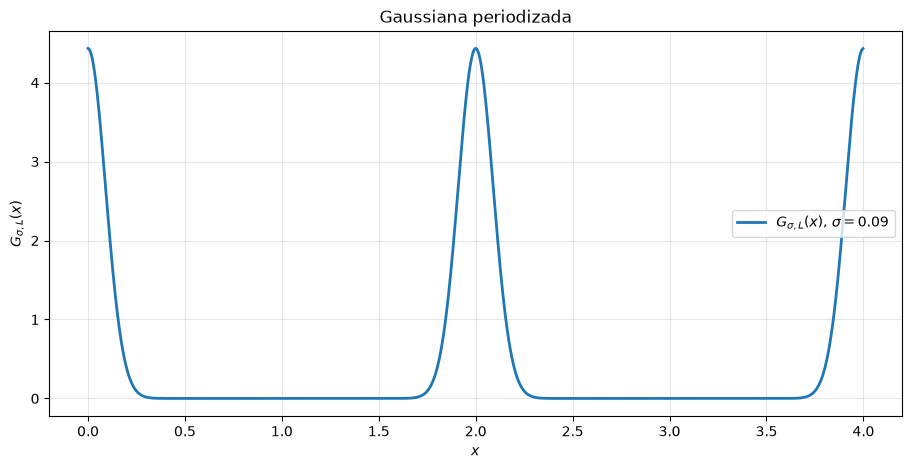

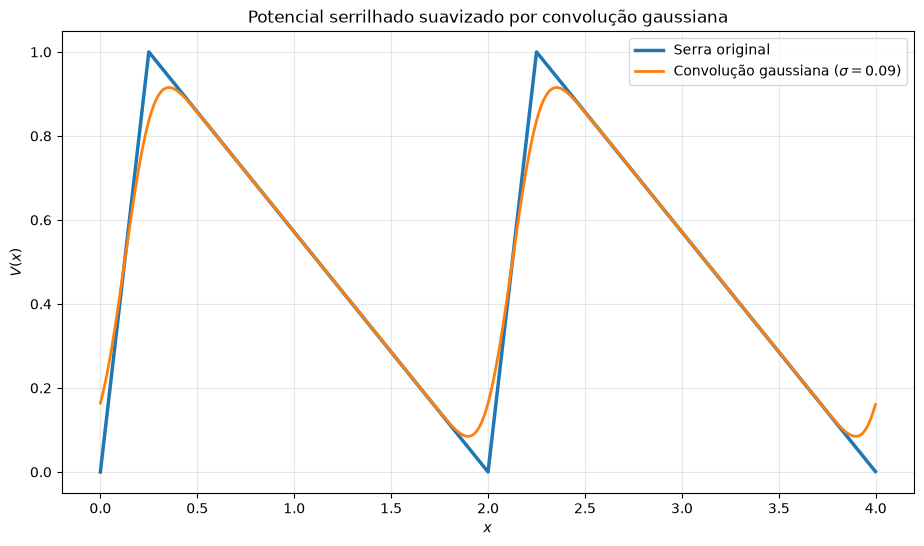

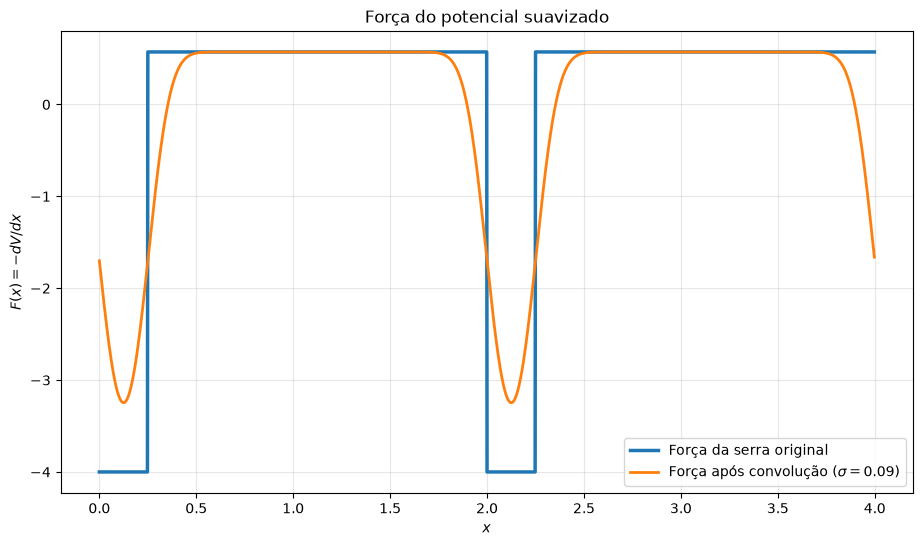

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros da serra e da gaussiana
V0 = 1.0
a = 1.75
b = 0.25
sigma = 0.09

L = a + b
x = np.linspace(0, 2 * L, 2000, endpoint=False)

def gaussiana_periodizada(x, n_imagens=5):
    resultado = np.zeros_like(np.asarray(x, dtype=float))
    for m in range(-n_imagens, n_imagens + 1):
        resultado += np.exp(-0.5 * ((x + m * L) / sigma)**2)
    return resultado / (np.sqrt(2 * np.pi) * sigma)

# Visualização do núcleo gaussiano periodizado
plt.figure(figsize=(11, 5))
plt.plot(x, gaussiana_periodizada(x), linewidth=2,
         label=fr"$G_{{\sigma,L}}(x)$, $\sigma={sigma}$")
plt.xlabel("$x$")
plt.ylabel(r"$G_{\sigma,L}(x)$")
plt.title("Gaussiana periodizada")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

def potencial_serra(x):
    x_mod = np.mod(x, L)
    return np.where(
        x_mod < b,
        V0 * x_mod / b,
        -V0 / a * (x_mod - b) + V0
    )

def forca_serra(x):
    x_mod = np.mod(x, L)
    return np.where(x_mod < b, -V0 / b, V0 / a)

# Coeficientes de Fourier da serra: a0 = V0
a0 = V0

def an(n):
    return (-V0 * L**2 / (np.pi**2 * a * b * n**2)
            * np.sin(np.pi * b * n / L)**2)

def bn(n):
    return (V0 * L**2 / (2 * np.pi**2 * a * b * n**2)
            * np.sin(2 * np.pi * b * n / L))

def potencial_suavizado(x, n_max=300):
    resultado = np.full_like(np.asarray(x, dtype=float), a0 / 2)
    for n in range(1, n_max + 1):
        kn = 2 * np.pi * n / L
        amortecimento = np.exp(-0.5 * (kn * sigma)**2)
        resultado += amortecimento * (
            an(n) * np.cos(kn * x) + bn(n) * np.sin(kn * x)
        )
    return resultado

def forca_suavizada(x, n_max=300):
    resultado = np.zeros_like(np.asarray(x, dtype=float))
    for n in range(1, n_max + 1):
        kn = 2 * np.pi * n / L
        amortecimento = np.exp(-0.5 * (kn * sigma)**2)
        resultado += amortecimento * kn * (
            an(n) * np.sin(kn * x) - bn(n) * np.cos(kn * x)
        )
    return resultado

# Potencial original e potencial convoluído
plt.figure(figsize=(11, 6))
plt.plot(x, potencial_serra(x), label="Serra original", linewidth=2.5)
plt.plot(x, potencial_suavizado(x), label=fr"Convolução gaussiana ($\sigma={sigma}$)", linewidth=2)
plt.xlabel("$x$")
plt.ylabel("$V(x)$")
plt.title("Potencial serrilhado suavizado por convolução gaussiana")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Força original e força correspondente ao potencial convoluído
plt.figure(figsize=(11, 6))
plt.plot(x, forca_serra(x), label="Força da serra original", linewidth=2.5)
plt.plot(x, forca_suavizada(x), label=fr"Força após convolução ($\sigma={sigma}$)", linewidth=2)
plt.xlabel("$x$")
plt.ylabel("$F(x)=-dV/dx$")
plt.title("Força do potencial suavizado")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Outra regularização: transições em tanh

Também podemos suavizar diretamente os saltos da força. A força original vale $f_1=-V_0/b$ no trecho $[0,b)$ e $f_2=V_0/a$ no trecho $[b,L)$. Substituímos a função indicadora do primeiro trecho por uma janela suave construída com tanh:

$$
S_\epsilon(x)=\frac12\sum_{m\in\mathbb Z}\left[\tanh\left(\frac{x-mL}{\epsilon}\right)-\tanh\left(\frac{x-b-mL}{\epsilon}\right)\right],\qquad F_\epsilon(x)=f_2+(f_1-f_2)S_\epsilon(x).
$$

A soma periodiza as transições nos pontos $0$ e $b$. O parâmetro $\epsilon$ determina a largura da região de transição: longe dos saltos, tanh tende a $\pm1$ e recuperamos os patamares da força.

A tanh também está ligada à regularização entrópica: $\tanh(z)=2/(1+e^{-2z})-1$, ou seja, é uma versão suave da escolha binária entre dois estados, dada pela função logística. A escala $\epsilon$ atua como temperatura/regularização; esta construção regulariza a força por uma transição logística suave.

Como a força de uma função periódica deve ter média zero em um período, a implementação remove o pequeno erro de média numérica e integra $-F_\epsilon$ cumulativamente para reconstruir o potencial.

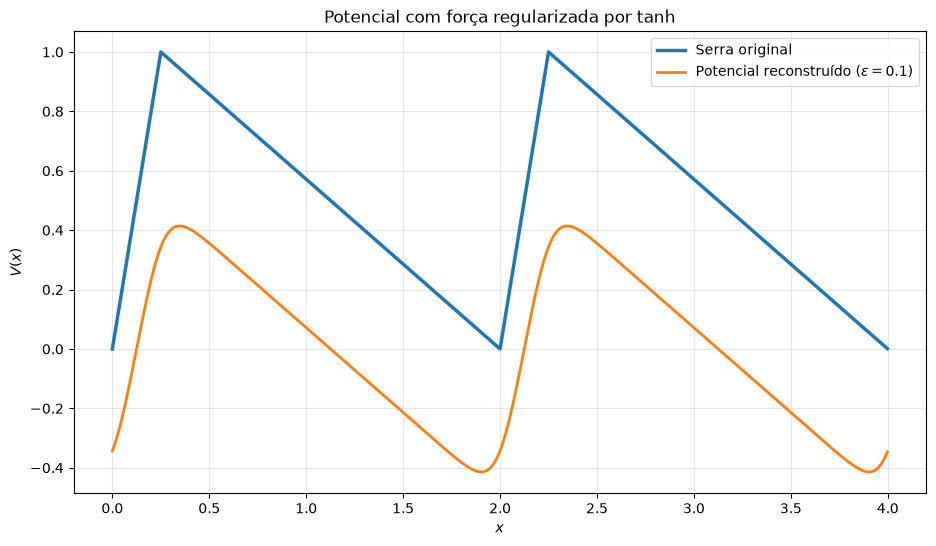

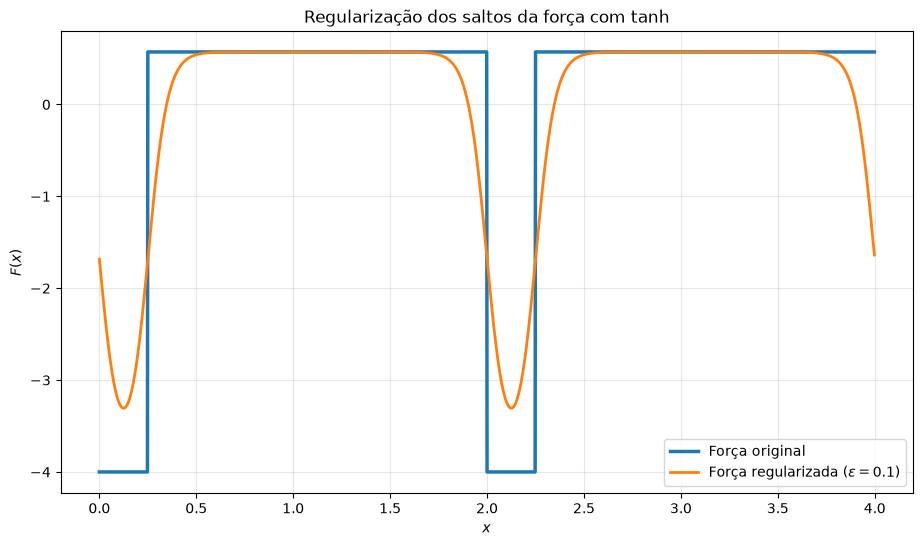

In [14]:
# Largura da regularização (em unidades de x)
epsilon = .1

def forca_tanh(x, n_imagens=5):
    x = np.asarray(x, dtype=float)
    f1, f2 = -V0 / b, V0 / a
    janela = np.zeros_like(x)
    for m in range(-n_imagens, n_imagens + 1):
        janela += 0.5 * (
            np.tanh((x - m * L) / epsilon)
            - np.tanh((x - b - m * L) / epsilon)
        )
    return f2 + (f1 - f2) * janela

# Força em dois períodos e correção numérica da média para garantir
# que o potencial reconstruído seja periódico na malha.
forca_regularizada = forca_tanh(x)
dx = x[1] - x[0]
forca_regularizada -= np.mean(forca_tanh(np.linspace(0, L, len(x)//2, endpoint=False)))

# Integra F=-dV/dx e fixa o nível médio do potencial em zero.
potencial_regularizado = np.zeros_like(x)
potencial_regularizado[1:] = np.cumsum(
    -0.5 * (forca_regularizada[1:] + forca_regularizada[:-1]) * dx
)
potencial_regularizado -= np.mean(potencial_regularizado)

plt.figure(figsize=(11, 6))
plt.plot(x, potencial_serra(x), label="Serra original", linewidth=2.5)
plt.plot(x, potencial_regularizado,
         label=fr"Potencial reconstruído ($\epsilon={epsilon}$)", linewidth=2)
plt.xlabel("$x$")
plt.ylabel("$V(x)$")
plt.title("Potencial com força regularizada por tanh")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(11, 6))
plt.plot(x, forca_serra(x), label="Força original", linewidth=2.5)
plt.plot(x, forca_regularizada,
         label=fr"Força regularizada ($\epsilon={epsilon}$)", linewidth=2)
plt.xlabel("$x$")
plt.ylabel("$F(x)$")
plt.title("Regularização dos saltos da força com tanh")
plt.grid(alpha=0.3)
plt.legend()
plt.show()